# Feature engineering y experimentos A/B del buscador (recuperación)

**Tesis:** *Desarrollo y evaluación de un chatbot educativo basado en IA generativa y RAG para reforzar el aprendizaje de cinemática preuniversitaria en una academia de Chachapoyas* — Elmer Dante Rojas Zuta (MIA-UNI).

El chatbot trabaja en dos pasos: primero **busca** fichas en el corpus y después el LLM **responde** con ellas. Este notebook ejecuta, paso a paso, la parte de búsqueda:

1. **Feature engineering:** cómo se transforma el texto (normalización, palabras vacías, raíces).
2. **Las cuatro variantes del buscador:** B0 (BM25), V1 (+ raíces), V2 (+ LSA) y V3 (+ enrutador de subtema), con un ejemplo real.
3. **Métrica:** Recall@k, calculada sobre el ejemplo.
4. **Validación cruzada** de 5 particiones en desarrollo (estratificada por subtema y agrupada por familia).
5. **Holdout de validación:** tabla estándar, diferencias con IC y gráfico Recall@k vs k.
6. **Verificación de cero leakage.**

El código reutiliza los módulos `src/rag/` y las funciones de `experiments/feature_engineering/ejecutar.py`, así que los resultados coinciden con los del informe. La evaluación final no se usa.

In [1]:
import sys, json, subprocess, time
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src")); sys.path.insert(0, str(RAIZ / "experiments/feature_engineering"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import eda_utils as u
from rag.preprocesamiento import tokens_basico, tokens_raices, PALABRAS_VACIAS
from rag.metricas import por_consulta, ic_bootstrap, diferencia_pareada
import ejecutar as ex

u.estilo(); pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 160)
corpus, preguntas, fuente = ex.cargar(None)
dev = preguntas[preguntas.particion == "desarrollo"].reset_index(drop=True)
val = preguntas[preguntas.particion == "validacion"].reset_index(drop=True)
titulo = {c["id"]: c["titulo"] for c in corpus}
print(f"Batería usada: {fuente}")
print(f"Corpus: {len(corpus)} fichas · preguntas respondibles: desarrollo {len(dev)} · validación {len(val)} · "
      f"evaluación final {(preguntas.particion == 'evaluacion_final').sum()} (no se usa)")

Batería usada: completa (privada)
Corpus: 136 fichas · preguntas respondibles: desarrollo 180 · validación 72 · evaluación final 108 (no se usa)


> **Nota.** Si existe la copia privada de la batería (`data/bateria/privado/`, fuera del repositorio), se usan las 360 preguntas respondibles. Desde un clon limpio se usa la batería pública, que omite los enunciados de las 50 preguntas de libros con derechos de autor; en ese caso los números cambian ligeramente.

## 1. Feature engineering: del texto a las features

El buscador no compara textos «tal cual»: compara **listas de términos**. Cada variante decide cómo se construye esa lista. Lo vemos con una pregunta real de la academia Ágora, de la partición de validación.

In [2]:
ej = val.set_index("id").loc["BAT-MRU-038"]
print("Pregunta:", ej.enunciado)
print("Fichas correctas (estándar de oro):", [f"{f} — {titulo[f]}" for f in ej.unidades_relevantes])

Pregunta: Un estudiante desea calcular la distancia que hay entre su casa y la academia. Si observa que caminando a razón de 80 cm/s tarda 25 min más que caminando a 95 cm/s, ¿cuál es la distancia entre su casa y la academia?
Fichas correctas (estándar de oro): ['CIN-MRU-P007 — Mismo recorrido con rapideces distintas', 'CIN-MRU-T010 — Conversión de unidades de rapidez']


In [3]:
basico = tokens_basico(ej.enunciado)
raices = tokens_raices(ej.enunciado)
print(f"B0 · normalización mínima ({len(basico)} términos):\n  ", " · ".join(basico))
print(f"\nV1 · sin palabras vacías ni números, con raíces ({len(raices)} términos):\n  ", " · ".join(raices))
quitadas = sorted({t for t in basico if t in PALABRAS_VACIAS or t.isdigit()})
print(f"\nPalabras eliminadas ({len(quitadas)}):", ", ".join(quitadas))

B0 · normalización mínima (44 términos):
   un · estudiante · desea · calcular · la · distancia · que · hay · entre · su · casa · y · la · academia · si · observa · que · caminando · a · razon · de · 80 · cm · s · tarda · 25 · min · mas · que · caminando · a · 95 · cm · s · cual · es · la · distancia · entre · su · casa · y · la · academia

V1 · sin palabras vacías ni números, con raíces (18 términos):
   estudi · dese · distanci · cas · academi · observ · camin · razon · cm · s · tard · min · camin · cm · s · distanci · cas · academi

Palabras eliminadas (17): 25, 80, 95, a, calcular, cual, de, entre, es, hay, la, mas, que, si, su, un, y


**Lectura.** La normalización deja minúsculas sin tildes. V1 elimina las palabras vacías («la», «que», «calcular»…) y los números, y reduce cada palabra a su raíz con Snowball: «caminando» → «camin», «distancia» → «distanci». A las 136 fichas del corpus se les aplica **la misma transformación**.

**Regla anti-fuga:** estas transformaciones son reglas fijas. Lo que aprende de datos (el IDF de BM25 y el TF-IDF/SVD del LSA) se ajusta **solo con el corpus**; ninguna pregunta participa en ese ajuste.

## 2. Las cuatro variantes del buscador con el ejemplo

In [4]:
enrutador = ex.entrenar_enrutador(corpus, dev)        # V3: aprende SOLO de corpus + preguntas de desarrollo
cfg = {v: dict(c) for v, c in ex.VARIANTES.items()}
cfg["V2"].update(alpha=0.5, dims_lsa=50)               # valores elegidos por validación cruzada (se comprueban en la sección 4)
cfg["V3"]["beta_subtema"] = 2.0

buscadores = {v: ex.indice(c, corpus, enrutador if v == "V3" else None)[0] for v, c in cfg.items()}

filas = []
for v, b in buscadores.items():
    top = [d for d, _ in b.buscar(ej.enunciado, 5)]
    filas.append({"variante": v, **{f"{i}.º": f"{'✔ ' if d in ej.unidades_relevantes else ''}{d.split('-')[1]} · {titulo[d]}" for i, d in enumerate(top, 1)}})
pd.DataFrame(filas).set_index("variante")

,1.º,2.º,3.º,4.º,5.º
variante,,,,,
B0,MCU · Poleas solidarias y faja,MRU · Eco frente a una montaña,MRUV · Distancia en el enésimo segundo,MPCL · Lanzamiento oblicuo desde una azotea,MRU · Tiempo de alcance
V1,MCU · Poleas solidarias y faja,✔ MRU · Mismo recorrido con rapideces distintas,MRU · Ida y vuelta: recorrido y distancia,MCU · Poleas unidas por una faja,MRUV · Distancia en el enésimo segundo
V2,✔ MRU · Mismo recorrido con rapideces distintas,MCU · Poleas solidarias y faja,MRU · Ida y vuelta: recorrido y distancia,MRUV · Distancia en el enésimo segundo,MCU · Poleas unidas por una faja
V3,✔ MRU · Mismo recorrido con rapideces distintas,MRU · Ida y vuelta: recorrido y distancia,"MRU · Moverse sobre algo que también se mueve: corriente, escalera...",MRU · Cinemática y movimiento mecánico,MRU · Problemas de eco y sonido


In [5]:
p = enrutador.proba(ej.enunciado)
print("Probabilidad de subtema que estima el enrutador (V3):")
for s, v in sorted(p.items(), key=lambda x: -x[1]): print(f"  {s:5s} {v:.2f}")

Probabilidad de subtema que estima el enrutador (V3):
  MRU   0.74
  MCU   0.11
  MRUV  0.06
  MVCL  0.05
  MPCL  0.04


**Lectura.**
- **B0** pone primero una ficha de **poleas (MCU)**: comparte «cm» y «s» con la pregunta, pero es de otro tema. Las preguntas de práctica describen una situación («caminando», «tarda más») sin nombrar el concepto.
- **V1**, gracias a las raíces, ya recupera la ficha correcta en 2.º lugar.
- **V2** también la sube al 1.er lugar en este ejemplo, pero mantiene fichas de MCU y MRUV entre las 5. En el conjunto de preguntas no mejora a V1 (sección 5): un ejemplo no basta para juzgar.
- **V3** suma al puntaje de cada ficha β × P(subtema). El enrutador estima MRU con alta probabilidad, así que las 5 fichas pasan a ser de MRU y la correcta queda **primera**.

## 3. La métrica: Recall@k, sobre el mismo ejemplo

Recall@k = (fichas correctas entre las k primeras) ÷ (fichas correctas de la pregunta). Se fija **k = 5** porque son las fichas que recibirá el LLM.

In [6]:
filas = []
for v, b in buscadores.items():
    rec = [d for d, _ in b.buscar(ej.enunciado, 10)]
    m = por_consulta(rec, set(ej.unidades_relevantes))
    filas.append(dict(variante=v, **{"Recall@1": m["recall@1"], "Recall@5": m["recall@5"], "Recall@10": m["recall@10"], "MRR@10": m["mrr@10"]}))
pd.DataFrame(filas).set_index("variante").round(2)

,Recall@1,Recall@5,Recall@10,MRR@10
variante,,,,
B0,0.0,0.0,0.0,0.0
V1,0.0,0.5,0.5,0.5
V2,0.5,0.5,0.5,1.0
V3,0.5,0.5,0.5,1.0


**Lectura.** Con V3, Recall@5 = 0,5: de las 2 fichas correctas, entra 1 entre las 5 primeras («Mismo recorrido con rapideces distintas»). Como sale primera, MRR@10 = 1. La otra ficha esperada, «Conversión de unidades de rapidez», no entra entre las 5.

## 4. Validación cruzada en desarrollo (5 particiones)

`StratifiedGroupKFold(5)`: cada partición conserva la proporción de subtemas (estratificada) y no separa preguntas de una misma familia (agrupada). En cada partición, los hiperparámetros de V2 (α y dimensiones) y de V3 (β, con una CV anidada de 3 particiones) se eligen **solo con la parte de entrenamiento**.

In [7]:
t0 = time.perf_counter()
cvdf, hp = ex.validacion_cruzada(corpus, dev)
print(f"Validación cruzada terminada en {time.perf_counter() - t0:.1f} s")
resumen_cv = cvdf.groupby("variante")[["recall@5", "recall@10", "mrr@10"]].agg(["mean", "std"]).round(3)
resumen_cv

Validación cruzada terminada en 8.4 s


recall@5        recall@10        mrr@10       
             mean    std      mean    std   mean    std
variante                                               
B0          0.434  0.111     0.535  0.105  0.379  0.084
V1          0.465  0.104     0.592  0.120  0.369  0.087
V2          0.459  0.120     0.595  0.111  0.364  0.079
V3          0.531  0.086     0.665  0.087  0.395  0.084

In [8]:
print("Hiperparámetros elegidos en cada partición:")
for h in hp["por_fold"]: print("  ", h)
print("Valores finales (con todo desarrollo):", hp["final"], "· β =", hp["final_v3"])
assert hp["final"] == {"alpha": 0.5, "dims_lsa": 50} and hp["final_v3"] == 2.0   # coinciden con los usados en la sección 2

Hiperparámetros elegidos en cada partición:
   {'fold': 1, 'alpha': 0.3, 'dims_lsa': 100}
   {'fold': 1, 'beta_subtema': 2.0}
   {'fold': 2, 'alpha': 0.5, 'dims_lsa': 50}
   {'fold': 2, 'beta_subtema': 2.0}
   {'fold': 3, 'alpha': 0.3, 'dims_lsa': 50}
   {'fold': 3, 'beta_subtema': 2.0}
   {'fold': 4, 'alpha': 0.3, 'dims_lsa': 50}
   {'fold': 4, 'beta_subtema': 2.0}
   {'fold': 5, 'alpha': 0.5, 'dims_lsa': 50}
   {'fold': 5, 'beta_subtema': 4.0}
Valores finales (con todo desarrollo): {'alpha': 0.5, 'dims_lsa': 50} · β = 2.0


**Lectura.** V3 tiene la media más alta de Recall@5 y la menor desviación entre particiones. β = 2 se elige en casi todas las particiones, así que la elección es estable.

## 5. Holdout de validación: la comparación oficial

Cada variante se ejecuta **una sola vez** sobre las 72 preguntas respondibles de validación, con su configuración final. El enrutador se entrena con todo desarrollo y nunca ve validación.

In [9]:
res = {}
for v, b in buscadores.items():
    res[v] = ex.evaluar(b, val)

filas = []
for v, r in res.items():
    lo, hi = ic_bootstrap(r["recall@5"])
    f = {"variante": v, "Recall@5": r["recall@5"].mean(), "IC95": f"[{lo:.3f}; {hi:.3f}]",
         "Recall@10": r["recall@10"].mean(), "MRR@10": r["mrr@10"].mean(), "Fallo@5": r["fallo@5"].mean(),
         "Subtema@1": r["acierto_subtema@1"].mean(), "Consulta (ms)": r.latencia_ms.mean()}
    if v != "B0":
        d = diferencia_pareada(res["B0"]["recall@5"], r["recall@5"])
        f.update({"Δ vs B0": d["diferencia"], "IC95 Δ": f"[{d['ic95'][0]:+.3f}; {d['ic95'][1]:+.3f}]", "p": d["p_bootstrap"]})
    filas.append(f)
tabla = pd.DataFrame(filas).set_index("variante")
tabla.round(3)

,Recall@5,IC95,Recall@10,MRR@10,Fallo@5,Subtema@1,Consulta (ms),Δ vs B0,IC95 Δ,p
variante,,,,,,,,,,
B0,0.377,[0.273; 0.479],0.488,0.285,0.583,0.708,0.765,NaN,NaN,NaN
V1,0.444,[0.340; 0.549],0.553,0.314,0.486,0.694,0.414,0.067,[-0.014; +0.150],0.103
V2,0.417,[0.312; 0.521],0.572,0.319,0.528,0.736,1.492,0.039,[-0.032; +0.111],0.286
V3,0.470,[0.361; 0.572],0.644,0.376,0.458,0.931,1.203,0.093,[+0.009; +0.181],0.031


In [10]:
d = diferencia_pareada(res["V1"]["recall@5"], res["V3"]["recall@5"])
print(f"V3 frente a V1: Δ = {d['diferencia']:+.3f} · IC95 [{d['ic95'][0]:+.3f}; {d['ic95'][1]:+.3f}] · p = {d['p_bootstrap']:.2f}")

V3 frente a V1: Δ = +0.025 · IC95 [-0.021; +0.065] · p = 0.26


**Lectura.**
- V3 sube Recall@5 de 0,377 a 0,470 frente a la línea base. Es la única mejora significativa: el IC de la diferencia no incluye el 0 y p ≈ 0,03.
- El acierto de subtema sube de ≈ 0,71 a ≈ 0,93.
- Frente a V1, la mejora de V3 es consistente pero no significativa con 72 preguntas.
- Ninguna variante usa la API del LLM: el costo es 0 y cada consulta tarda alrededor de un milisegundo. Los tiempos varían entre ejecuciones; las métricas no.

### Gráfico clave: Recall@k vs k

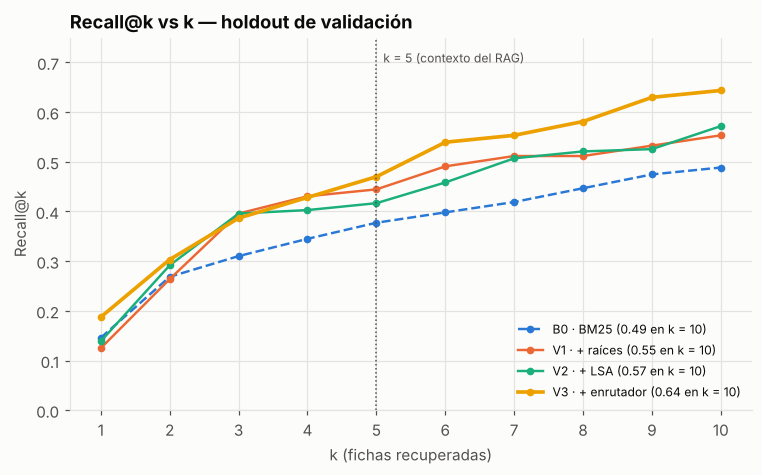

,1,2,3,4,5,6,7,8,9,10
B0,0.146,0.269,0.310,0.345,0.377,0.398,0.419,0.447,0.475,0.488
V1,0.125,0.264,0.396,0.431,0.444,0.491,0.512,0.512,0.532,0.553
V2,0.139,0.292,0.396,0.403,0.417,0.458,0.507,0.521,0.525,0.572
V3,0.188,0.303,0.387,0.428,0.470,0.539,0.553,0.581,0.630,0.644


In [11]:
curva = pd.DataFrame({v: [r[f"recall@{k}"].mean() for k in range(1, 11)] for v, r in res.items()}, index=range(1, 11))
etiquetas = {"B0": "B0 · BM25", "V1": "V1 · + raíces", "V2": "V2 · + LSA", "V3": "V3 · + enrutador"}
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, v in enumerate(curva.columns):
    ax.plot(curva.index, curva[v], "--" if v == "B0" else "-", marker="o", ms=4, lw=2.4 if v == "V3" else 1.6,
            color=u.SERIE[i], label=f"{etiquetas[v]} ({curva[v].iloc[-1]:.2f} en k = 10)")
ax.axvline(5, color=u.TINTA_2, ls=":", lw=1); ax.text(5.1, 0.70, "k = 5 (contexto del RAG)", color=u.TINTA_2, fontsize=8)
ax.set_xticks(range(1, 11)); ax.set_ylim(0, 0.75); ax.set_xlabel("k (fichas recuperadas)"); ax.set_ylabel("Recall@k")
ax.set_title("Recall@k vs k — holdout de validación"); ax.legend(loc="lower right", fontsize=8)
plt.show()
curva.round(3).T

**Lectura.** V3 queda por encima desde k = 4 y su ventaja crece con k. Entre k = 1 y k = 3 las variantes casi no se distinguen.

### Por segmento y análisis de fallos

In [12]:
seg = pd.DataFrame({v: r.groupby("componente")["recall@5"].mean() for v, r in res.items()}).round(2)
seg.loc["cobertura parcial"] = [r.loc[r.cobertura_parcial, "recall@5"].mean() for r in res.values()]
display(seg)
f3 = res["V3"][res["V3"]["fallo@5"] == 1]
print(f"V3 falla en {len(f3)} de {len(res['V3'])} preguntas; en {int(f3['acierto_subtema@1'].sum())} de esos fallos "
      f"la primera ficha sí es del subtema correcto.")

,B0,V1,V2,V3
componente,,,,
practica,0.22,0.30,0.26,0.32
teoria,0.84,0.89,0.89,0.91
cobertura parcial,0.00,0.00,0.00,0.00


V3 falla en 33 de 72 preguntas; en 29 de esos fallos la primera ficha sí es del subtema correcto.


**Lectura.** En teoría la recuperación ya funciona bien; el reto está en la práctica. Cuando V3 falla, casi siempre acierta el subtema: falta la **ficha exacta**, sea porque la anotación es estrecha o porque el tema no tiene ficha (cobertura parcial). Esto orienta el corpus v6.

## 6. Verificación de cero leakage

El script `verificar_fugas.py` comprueba la partición, las familias, la ausencia de preguntas copiadas en el corpus y que los logs solo contengan preguntas de validación.

In [13]:
salida = subprocess.run([sys.executable, str(RAIZ / "experiments/feature_engineering/verificar_fugas.py")],
                        capture_output=True, text=True, cwd=RAIZ)
print(salida.stdout)
v = json.load(open(RAIZ / "experiments/feature_engineering/resultados/verificacion_fugas.json", encoding="utf-8"))
assert v["todo_ok"], "La verificación de cero leakage falló"

bateria_usada → completa (privada) 
1_copias_en_corpus → OK {'preguntas_revisadas': 400, 'jaccard_maximo': 0.451, 'preguntas_con_jaccard_mayor_0_5': 0}
2_particion → OK {'conteos': {'desarrollo': 200, 'evaluacion_final': 120, 'validacion': 80}, 'desviacion_maxima': {'estrato (teoría / práctica×nivel / no respondible)': 0.0, 'subtema': 0.0}, 'practica_subtema_nivel_desarrollo_siempre_9': True}
3_familias → OK {'familias': 395, 'familias_con_varias_preguntas': 5, 'familias_partidas': 0}
4_validacion_cruzada → OK {}
5_evaluacion_final_intacta → OK {'runs': 4, 'consultas_por_particion': {'validacion': 288}}
6_textos_protegidos_en_logs → OK {'expuestos': 0}
todo_ok → True 



## 7. Conclusiones

1. **Feature engineering:** las raíces y la eliminación de palabras vacías ayudan algo (V1). El LSA, ajustado con solo 136 fichas, no aporta (V2) y se sustituirá por embeddings preentrenados.
2. **Variante elegida: V3** (raíces + enrutador de subtema, β = 2). Mejora Recall@5 frente a la línea base de forma significativa, sube el acierto de subtema a ≈ 93 % y no tiene costo de API.
3. **Validación:** la validación cruzada y el holdout dan el mismo orden de variantes. La evaluación final sigue sin usarse.
4. **Siguiente paso:** corpus v6 (fichas nuevas y ejemplos resueltos) y el experimento de generación, que compara el LLM solo con el LLM + RAG (V3).